# 영상 채널 성과 분석 (2019–2021) — 공개 분석 노트북

직접 운영했던 영상 채널의 YouTube Studio 데이터로 데이터 정합성, 유입 경로, KPI를 분석한 노트북입니다. **이 노트북은 공개된 `data/processed/` 파일만 사용하며, 저장소를 내려받으면 그대로 실행됩니다.** 주요 수치와 차트는 공개 데이터에 근거하며, 이 노트북에서 핵심 계산과 분모를 확인할 수 있습니다.

### 데이터 흐름
1. **비공개 원본** (`data/raw/`, 공개하지 않음): YouTube Studio 고급 모드 CSV(본인 채널, 2026-11-02 추출)와 콘텐츠→코드 매핑 파일
2. **전처리** (`scripts/build_public_data.py`): 원본에서 공개용 CSV를 만드는 스크립트. 원본이 있어야 실행됩니다.
3. **공개 분석** (이 노트북): `data/processed/`만 읽어 계산과 차트를 재현합니다.

### 공개 데이터의 세 가지 수준
| 수준 | 파일 | 이 노트북에서 재계산 |
|---|---|---|
| **채널 단위 원본 값** — 반올림 없음 | `channel_totals`, `channel_daily_views_2019_2021`, `traffic_sources_2019_2021`, `traffic_by_period_source`, `monthly_views_by_source`, `subscribers_daily_2019_2021`, `aggregation_check` | 가능 (비율·합계) |
| **영상별 원본에서 계산한 집계값** — 반올림 없음 | `exact_aggregates` | 불가 (결과값만 공개) |
| **영상별 공개용 값** — 연도·길이 구간·반올림 | `videos_2019_2021_public` | 가능 (반올림 값 기준) |

공개 CSV로 계산 과정은 확인할 수 있지만, 공개 데이터가 원본과 일치하는지는 독립적으로 검증할 수 없습니다.

**지표 명칭:** '조회수'는 모두 YouTube Studio의 **'유효 조회수'** 열입니다.

**표기:** [관측] 원본 값 그대로 · [계산] 합·차·비율(분자·분모 명시) · [참고] 가정을 둔 계산값 · [추정] 근거는 있으나 확인 불가 · [가설] 검증하지 않은 해석

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
P = 'data/processed'
SPIKE = ('2019-03-09', '2019-03-22')
for f in ['Pretendard', 'Noto Sans CJK KR', 'AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if any(f in x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = f; break
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.unicode_minus': False, 'figure.dpi': 110})
BLUE, DARK, SLATE, LIGHT = '#2196F3', '#202020', '#64748B', '#CBD5E1'
pd.options.display.float_format = lambda x: f'{x:,.4f}'.rstrip('0').rstrip('.')

kv = lambda f: pd.read_csv(f'{P}/{f}').set_index('key')['value']
tot = kv('channel_totals.csv')
exa = kv('exact_aggregates.csv')
agg = pd.read_csv(f'{P}/aggregation_check.csv').set_index('metric')
daily = pd.read_csv(f'{P}/channel_daily_views_2019_2021.csv', parse_dates=['date']).set_index('date')['views']
tps = pd.read_csv(f'{P}/traffic_by_period_source.csv')
ts = pd.read_csv(f'{P}/traffic_sources_2019_2021.csv')
monthly = pd.read_csv(f'{P}/monthly_views_by_source.csv').set_index('month')
subs = pd.read_csv(f'{P}/subscribers_daily_2019_2021.csv', parse_dates=['date']).set_index('date')['subs_net']
pub = pd.read_csv(f'{P}/videos_2019_2021_public.csv')
print('불러온 공개 파일 9개 · 분석 기간', daily.index.min().date(), '~', daily.index.max().date())

불러온 공개 파일 9개 · 분석 기간 2019-01-13 ~ 2021-12-31


## 1. 지표 기준과 분석 기간

In [2]:
views = int(float(tot['views_2019_2021'])); life = int(float(tot['views_lifetime_effective']))
assert int(daily.sum()) == views
print('[관측] 전체 기간 합계: 유효 조회수 %d / 일반 조회수 %d (분석 기간 2019–2021에는 두 열의 값이 같음)' % (int(float(tot['views_lifetime_effective'])), int(float(tot['views_lifetime_plain']))))
print('[관측] 채널 합계(2019–2021): 썸네일 노출수 %d · CTR %.2f%% · 유효 조회수 %d · 시청 시간 %.4f시간 · 구독 순증가 %+d' % (float(tot['impr_2019_2021']), float(tot['ctr_2019_2021']), views, float(tot['watch_h_2019_2021']), float(tot['subs_2019_2021'])))
print('[계산] 분석 기간 유효 조회수 / 전체 기간 유효 조회수 = %d / %d = %.1f%%' % (views, life, views / life * 100))

[관측] 전체 기간 합계: 유효 조회수 129374 / 일반 조회수 129378 (분석 기간 2019–2021에는 두 열의 값이 같음)
[관측] 채널 합계(2019–2021): 썸네일 노출수 2868407 · CTR 3.42% · 유효 조회수 123577 · 시청 시간 5749.6093시간 · 구독 순증가 +218
[계산] 분석 기간 유효 조회수 / 전체 기간 유효 조회수 = 123577 / 129374 = 95.5%


## 2. 집계 범위 점검 (Q1)

YouTube는 삭제된 콘텐츠의 기록도 채널 합계에 남깁니다. 동일 기간·필터에서 모든 콘텐츠가 포함되면 유효 조회수·시청 시간·노출수는 합산 가능하므로, 차이를 **현존 영상 목록에서 확인되지 않는 성과(잔여분)**로 봅니다(현존 영상 목록이 완전하다는 전제). 구독은 채널 페이지 등 영상 밖에서도 발생할 수 있어 집계 범위가 달라, 차이를 어떤 영상에도 귀속하지 않습니다.

In [3]:
a = agg.copy()
for c in ['channel_total', 'existing_videos_sum', 'difference']: a[c] = a[c].astype(float)
a['existing_share_%'] = (a.existing_videos_sum / a.channel_total * 100).round(1)
a['difference_share_%'] = (a.difference / a.channel_total * 100).round(1)
a.loc['구독 순증가', 'difference_share_%'] = None
a

,channel_total,existing_videos_sum,difference,interpretation,existing_share_%,difference_share_%
metric,,,,,,
유효 조회수,"123,577","51,168","72,409",현존 목록 밖 성과(잔여분),41.4,58.6
시청 시간(시간),"5,749.6093","2,474.0452","3,275.5641",현존 목록 밖 성과(잔여분),43,57
썸네일 노출수,"2,868,407","292,404","2,576,003",현존 목록 밖 성과(잔여분),10.2,89.8
구독 순증가,218,77,141,집계 범위 차이 — 특정 영상에 귀속하지 않음,35.3,NaN


- **[계산]** 현존 9개 영상의 유효 조회수는 채널 합계의 41.4%이며, 잔여분 비중은 유효 조회수 58.6% · 시청 시간 57.0% · 노출수 89.8%입니다.
- **[계산]** 구독 차이(+141명)는 집계 범위 차이로만 표시합니다.

## 3. 일별 모니터링: 급증 14일 (Q2)

[계산] 급증 14일 유효 조회수 / 분석 기간 = 70636 / 123577 = 57.2%
[관측] 급증 14일 일별 유효 조회수: 386–14278회 (일평균 5045회)
[계산] 직전 4주(2019-02-09~03-08) 일평균 75.4회 → 급증 14일 일별 값은 그 5–189배
[관측] 3월 22일 14278회 → 3월 23일 46회

[관측] 급증 시작 전 게시된 현존 영상: L1 · L1 일별 18–68회 (직전 4주 일평균 47.9회)
[계산] 급증 14일 중 현존 영상 외 = 70636 − L1 508 = 70128회 → 잔여분 72409회의 96.8%
[관측] 급증 이후(2019-03-23~07-21) 현존 영상 외 유효 조회수: 1181회
[참고] 잔여분 평균 시청 지속 시간 = 3275.5641시간 × 3600 ÷ 72409 = 163초
[계산] 급증기 현존 목록 밖 비중 = 99.3%; L1 급증기 일평균 = 36.3회


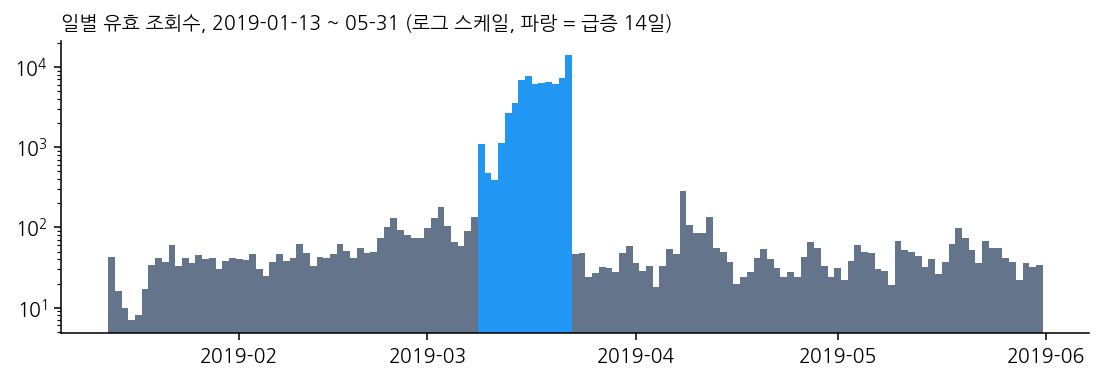

In [4]:
sp = daily[SPIKE[0]:SPIKE[1]]; prior = daily['2019-02-09':'2019-03-08']
print('[계산] 급증 14일 유효 조회수 / 분석 기간 = %d / %d = %.1f%%' % (sp.sum(), views, sp.sum() / views * 100))
print('[관측] 급증 14일 일별 유효 조회수: %d–%d회 (일평균 %.0f회)' % (sp.min(), sp.max(), sp.mean()))
print('[계산] 직전 4주(2019-02-09~03-08) 일평균 %.1f회 → 급증 14일 일별 값은 그 %.0f–%.0f배' % (prior.mean(), sp.min() / prior.mean(), sp.max() / prior.mean()))
print('[관측] 3월 22일 %d회 → 3월 23일 %d회' % (daily['2019-03-22'], daily['2019-03-23']))

resid = int(float(agg.loc['유효 조회수', 'difference']))
l1 = int(exa['l1_spike_views'])
print()
print('[관측] 급증 시작 전 게시된 현존 영상: %s · L1 일별 %s–%s회 (직전 4주 일평균 %s회)' % (exa['existing_before_spike'], exa['l1_spike_daily_min'], exa['l1_spike_daily_max'], exa['l1_prior4w_daily_mean']))
print('[계산] 급증 14일 중 현존 영상 외 = %d − L1 %d = %d회 → 잔여분 %d회의 %.1f%%' % (sp.sum(), l1, sp.sum() - l1, resid, (sp.sum() - l1) / resid * 100))
print('[관측] 급증 이후(2019-03-23~07-21) 현존 영상 외 유효 조회수: %s회' % exa['unlisted_views_after_spike'])
print('[참고] 잔여분 평균 시청 지속 시간 = %.4f시간 × 3600 ÷ %d = %.0f초' % (float(agg.loc['시청 시간(시간)', 'difference']), resid, float(agg.loc['시청 시간(시간)', 'difference']) * 3600 / resid))

fig, ax = plt.subplots(figsize=(8, 2.8))
w = daily['2019-01-13':'2019-05-31']
ax.bar(w.index, w.values, color=[BLUE if SPIKE[0] <= str(d.date()) <= SPIKE[1] else SLATE for d in w.index], width=1)
ax.set_yscale('log'); ax.set_title('일별 유효 조회수, 2019-01-13 ~ 05-31 (로그 스케일, 파랑 = 급증 14일)', fontsize=10, loc='left')
plt.tight_layout(); plt.show()
print('[계산] 급증기 현존 목록 밖 비중 = %.1f%%; L1 급증기 일평균 = %.1f회' % ((sp.sum()-l1)/sp.sum()*100,l1/len(sp)))


- **[관측]** 2019년 3월 9–22일 일별 유효 조회수는 386–14,278회로, 직전 4주 일평균(75회)의 약 5–189배였습니다. 3월 22일 14,278회에서 다음 날 46회로 감소했습니다. 이 14일이 분석 기간 유효 조회수의 57.2%입니다.
- **[계산]** 급증 당시 게시돼 있던 현존 영상은 L1뿐이며, 일평균 36.3회로 직전 4주 47.9회에 비해 채널 전체와 같은 급증은 없었습니다. 급증 유효 조회수 중 70,128회는 현존 영상 목록에서 확인되지 않는 콘텐츠에서 발생했고, 이는 급증기 조회수의 99.3%이며, 전체 잔여분의 96.8%입니다.
- **[관측]** YouTube Studio 콘텐츠 목록에 '삭제됨'으로 표시된 영상이 1개(예능 하이라이트 편집, 길이 2–5분) 있습니다. 삭제 날짜와 사유는 기록으로 확인하지 못했습니다.
- **[추정]** 확인된 삭제 영상이 급증에 기여했을 가능성은 있지만, 영상별 기록이 없어 기여 규모는 확인하지 못했습니다. 3월 23일 급감 이후(3월 23일~7월 21일)에도 현존 목록 밖 조회수가 1,181회 발생했습니다. 조회수 급감 시점과 삭제 시점을 동일하게 볼 수 없으며, 특정 영상의 기여·삭제 시점·개수·원인은 미확인입니다.
- **[참고]** 잔여분의 평균 시청 지속 시간(163초)은 여러 콘텐츠가 섞였을 수 있는 집계값이므로, 특정 삭제 영상을 식별하는 근거로 사용하지 않습니다.

## 4. 기간별 유입 구조 (Q2)

group   추천·탐색     검색    기타     합계
period                           
급증 14일  68459   1170  1007  70636
나머지 기간   3439  44155  5347  52941
group   추천·탐색   검색   기타
period                 
급증 14일   96.9  1.7  1.4
나머지 기간    6.5 83.4 10.1
[계산] 추천 동영상 유입 중 급증 14일 비중 = 56823 / 57553 = 98.73%
[관측] 검색 유입: 2020년 19814회 → 2021년 9641회


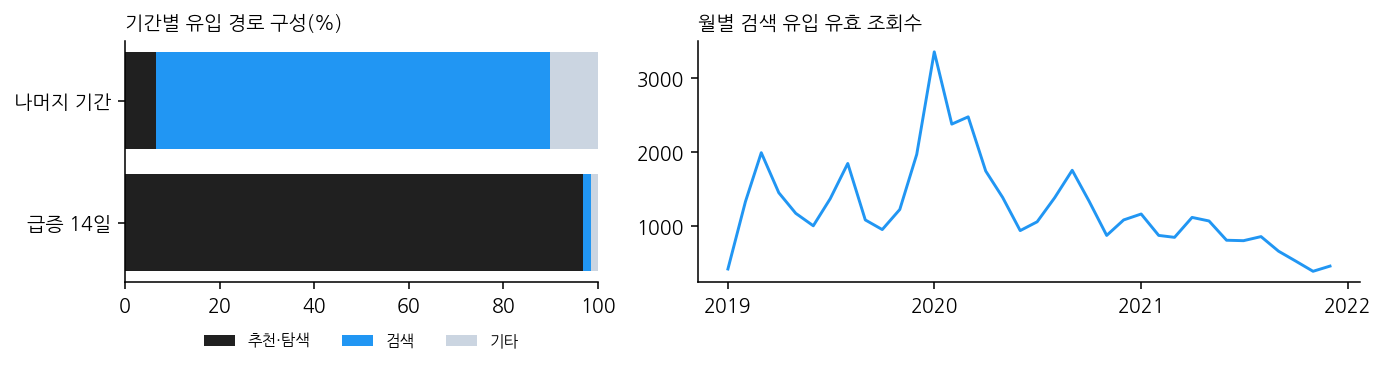

In [5]:
G = {'추천 동영상': '추천·탐색', '탐색 기능': '추천·탐색', 'YouTube 검색': '검색'}
tps['group'] = tps.source.map(G).fillna('기타')
mix = tps.pivot_table(index='period', columns='group', values='views', aggfunc='sum')[['추천·탐색', '검색', '기타']]
mix['합계'] = mix.sum(axis=1)
share = mix[['추천·탐색', '검색', '기타']].div(mix['합계'], axis=0).mul(100).round(1)
print(mix); print(share)
rec = tps[tps.source == '추천 동영상'].set_index('period').views
print('[계산] 추천 동영상 유입 중 급증 14일 비중 = %d / %d = %.2f%%' % (rec['급증 14일'], rec.sum(), rec['급증 14일'] / rec.sum() * 100))
assert mix['합계'].sum() == views

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), gridspec_kw={'width_ratios': [1, 1.4]})
left = 0
for g, c in zip(['추천·탐색', '검색', '기타'], [DARK, BLUE, LIGHT]):
    axes[0].barh(share.index, share[g], left=left, color=c, label=g); left = left + share[g]
axes[0].set_xlim(0, 100); axes[0].legend(fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(.5, -0.15), frameon=False)
axes[0].set_title('기간별 유입 경로 구성(%)', fontsize=10, loc='left')
axes[1].plot(pd.to_datetime(monthly.index), monthly['검색'], color=BLUE)
import matplotlib.dates as mdates
axes[1].xaxis.set_major_locator(mdates.YearLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[1].set_title('월별 검색 유입 유효 조회수', fontsize=10, loc='left'); plt.tight_layout(); plt.show()
print('[관측] 검색 유입: 2020년 %d회 → 2021년 %d회' % (monthly.loc[monthly.index.str.startswith('2020'), '검색'].sum(), monthly.loc[monthly.index.str.startswith('2021'), '검색'].sum()))

- **[계산]** 급증 14일 유효 조회수(70,636회)의 96.9%는 추천·탐색에서, 급증 14일을 제외한 나머지 기간(52,941회)의 83.4%는 검색에서 발생했습니다. 추천 동영상 유입 전체의 98.73%가 급증 14일에 몰려 있습니다.
- **[관측]** 나머지 기간의 주요 유입 경로는 검색이었습니다. 검색 유입은 관찰 기간 내내 매달 발생했고 2020년 이후 전반적으로 감소했습니다. 이는 관측된 구성비이며, 검색이 성과를 만들었다는 인과관계나 이후에도 유지되는 수요를 뜻하지 않습니다.

## 5. 유입 경로별 지표 (Q3)

In [6]:
t = ts.set_index('source'); T = t.loc['합계']
m = t.loc[['추천 동영상', 'YouTube 검색', '탐색 기능']].copy()
m['impr_share_%'] = (m.impr / T.impr * 100).round(1); m['view_share_%'] = (m.views / T.views * 100).round(1)
print('[참고] 썸네일 노출수 × CTR = %.0f회 vs 유효 조회수 %d회 — 모든 조회가 집계 대상 썸네일 노출에서 발생하지는 않음' % (T.impr * T.ctr / 100, T.views))
m[['impr', 'impr_share_%', 'ctr', 'views', 'view_share_%', 'pct_viewed', 'avg_view_s']]
print('[계산] 검색/추천 CTR 비 = %.2f배; 평균 시청 지속 시간 차이 = %d초' % (m.loc['YouTube 검색','ctr']/m.loc['추천 동영상','ctr'],m.loc['추천 동영상','avg_view_s']-m.loc['YouTube 검색','avg_view_s']))


[참고] 썸네일 노출수 × CTR = 98100회 vs 유효 조회수 123577회 — 모든 조회가 집계 대상 썸네일 노출에서 발생하지는 않음
[계산] 검색/추천 CTR 비 = 8.36배; 평균 시청 지속 시간 차이 = 22초


- **[관측]** 추천은 노출 비중 84.3%·CTR 1.84%, 검색은 노출 비중 9.2%·CTR 15.39%였고, 평균 조회율은 추천 57.6%, 검색 10.4%였습니다.
- **[해석]** 경로별 평균 조회율 차이에는 이용자 특성뿐 아니라 경로별로 소비된 영상의 길이·콘텐츠 구성 차이가 함께 영향을 미쳤을 수 있습니다. 같은 시간을 시청했다면 긴 영상일수록 조회율은 낮게 나옵니다. 영상별 유입 경로 자료가 없어 분리할 수 없으므로 경로 자체의 시청 품질을 판단하지 않습니다. CTR도 경로의 우열로 해석하지 않습니다.
- **[계산]** 검색/추천 CTR 비는 약 8.4배이지만 평균 시청 지속 시간은 143초와 165초로 22초 차이입니다. 지표마다 드러나는 성과의 모습이 다르며, 길이·콘텐츠 구성 차이는 분리하지 못했습니다.


## 6. 영상별 시청 성과와 KPI (Q4)

영상별 값은 **공개용 반올림 값**입니다(게시 연도, 길이 구간, 노출수 100·유효 조회수 10·평균 시청 지속 시간 10초 단위, 평균 조회율 정수, 시청 시간 정수). 시청 성과 비교에서는 유효 조회수 30회인 P1만 제외하고, CTR은 노출 5,000회 이상 영상만 해석합니다(분석자가 정한 탐색 기준). 게시 시점이 달라 누적값은 분석 기간의 채널 성과 기여도입니다.

[관측·공개값] 롱폼: 평균 조회율 11–16% / 평균 시청 지속 시간 약 210–270초
[관측·공개값] 5분 미만(S1,M2,C1,C2): 평균 조회율 26–79% / 평균 시청 지속 시간 약 30–60초
[계산] 롱폼 시청 시간 비중: 원본 2205.4977 / 5749.6093 = 38.4% · 공개값 2205 / 5749.6093 = 38.4%


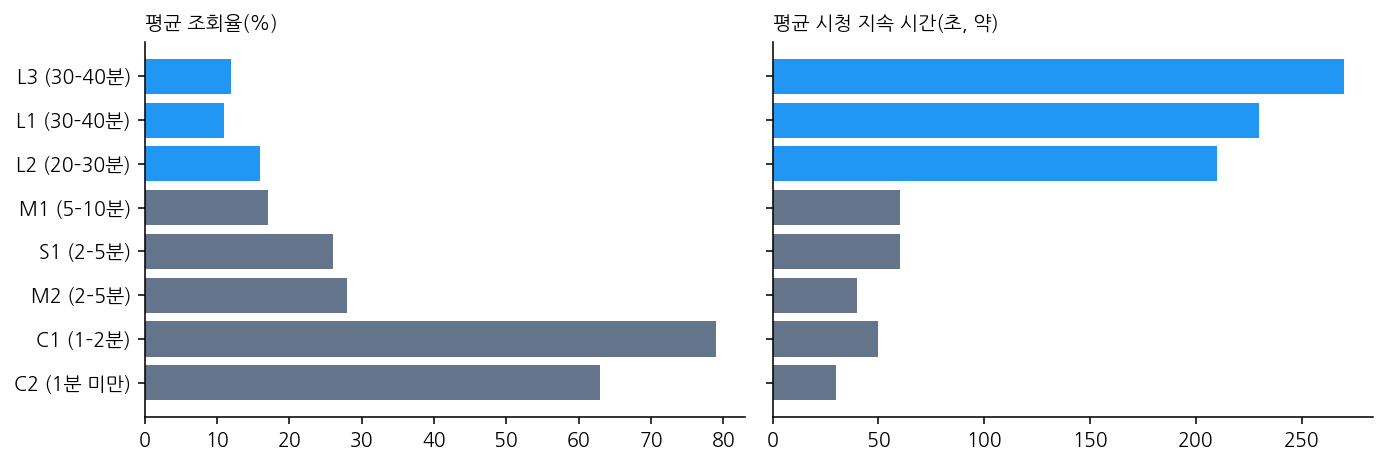

,code,type,year,length_band,impr,ctr,views,avg_view_s,pct_viewed,watch_h,subs
1,L3,롱폼 음성 콘텐츠,2019,30–40분,29600,11.9,4110,270,12,312,3
2,L1,롱폼 음성 콘텐츠,2019,30–40분,127700,17,25600,230,11,1611,31
3,L2,롱폼 음성 콘텐츠,2019,20–30분,44800,8.7,4840,210,16,282,13
4,M1,편집 영상,2019,5–10분,4100,3.3,200,60,17,4,0
5,S1,콘셉트 영상(영상통화 형식),2019,2–5분,65800,19.1,14860,60,26,245,29
6,M2,편집 영상,2020,2–5분,2000,11.5,270,40,28,3,0
7,C1,예능 클립,2019,1–2분,12900,6.4,1000,50,79,14,1
8,C2,예능 클립,2019,1분 미만,5400,3.6,250,30,63,2,1


In [7]:
cmp = pub[pub.code != 'P1'].sort_values('length_rank')
short = cmp[cmp.length_band.isin(['1분 미만', '1–2분', '2–5분'])]; lg = cmp[cmp.code.str.startswith('L')]
print('[관측·공개값] 롱폼: 평균 조회율 %d–%d%% / 평균 시청 지속 시간 약 %d–%d초' % (lg.pct_viewed.min(), lg.pct_viewed.max(), lg.avg_view_s.min(), lg.avg_view_s.max()))
print('[관측·공개값] 5분 미만(%s): 평균 조회율 %d–%d%% / 평균 시청 지속 시간 약 %d–%d초' % (','.join(short.code), short.pct_viewed.min(), short.pct_viewed.max(), short.avg_view_s.min(), short.avg_view_s.max()))
cw = float(tot['watch_h_2019_2021'])
print('[계산] 롱폼 시청 시간 비중: 원본 %.4f / %.4f = %.1f%% · 공개값 %d / %.4f = %.1f%%' % (float(exa['long_form_watch_h']), cw, float(exa['long_form_watch_h']) / cw * 100, lg.watch_h.sum(), cw, lg.watch_h.sum() / cw * 100))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
col = [BLUE if c.startswith('L') else SLATE for c in cmp.code]
lab = [f'{c} ({b})' for c, b in zip(cmp.code, cmp.length_band)]
axes[0].barh(lab, cmp.pct_viewed, color=col); axes[0].set_title('평균 조회율(%)', fontsize=10, loc='left'); axes[0].invert_yaxis()
axes[1].barh(lab, cmp.avg_view_s, color=col); axes[1].set_title('평균 시청 지속 시간(초, 약)', fontsize=10, loc='left')
plt.tight_layout(); plt.show()
cmp[['code', 'type', 'year', 'length_band', 'impr', 'ctr', 'views', 'avg_view_s', 'pct_viewed', 'watch_h', 'subs']]

### 공개용 반올림 값과 원본 집계값의 차이

영상별 공개 값을 더한 결과는 원본 합계와 조금 다릅니다. 결과 페이지의 **채널 합계와 비율(41.4%, 57.2%, 38.4% 등)은 원본 값**으로, **영상별 표·차트·범위(예: 약 210–270초)는 공개용 값**으로 표시합니다.

In [8]:
ex = pub[['impr', 'views', 'watch_h', 'subs']].sum()
diff = pd.DataFrame({
    '원본 합계(현존 9개)': [float(agg.loc['썸네일 노출수', 'existing_videos_sum']), float(agg.loc['유효 조회수', 'existing_videos_sum']), float(agg.loc['시청 시간(시간)', 'existing_videos_sum']), float(agg.loc['구독 순증가', 'existing_videos_sum'])],
    '공개값 합계': [ex.impr, ex.views, ex.watch_h, ex.subs]}, index=['썸네일 노출수', '유효 조회수', '시청 시간(시간)', '구독 순증가'])
diff['차이'] = diff['공개값 합계'] - diff['원본 합계(현존 9개)']
diff['차이율(%)'] = (diff['차이'] / diff['원본 합계(현존 9개)'] * 100).round(3)
diff

,원본 합계(현존 9개),공개값 합계,차이,차이율(%)
썸네일 노출수,"292,404",292500,96,0.033
유효 조회수,"51,168",51160,-8,-0.016
시청 시간(시간),"2,474.0452",2473,-1.0452,-0.042
구독 순증가,77,77,0,0


- **[관측]** 이번 비교 대상에서는 짧은 영상이 평균 조회율에서, 긴 음성 콘텐츠가 평균 시청 지속 시간에서 높은 값을 보였습니다. 롱폼 3개는 채널 시청 시간의 38.4%를 차지했습니다(원본·공개값 모두 38.4%).
- **[해석]** 지표별 결과가 달랐으므로 콘텐츠 목적에 맞는 KPI 선택이 필요합니다. 사례 수가 적고 길이·주제·게시 시점이 함께 달라 유형의 효과를 입증한 것은 아닙니다.
- **[후속 확인]** L1(17.0%)·S1(19.1%)의 높은 CTR이 유입 경로 구성 때문인지 영상 자체의 특성 때문인지 추가 확인이 필요합니다. 영상별 유입 경로 자료가 없어 두 영향을 구분할 수 없습니다.

## 7. 구독 지표

In [9]:
assert int(subs.sum()) == int(float(tot['subs_2019_2021']))
ss = int(subs[SPIKE[0]:SPIKE[1]].sum())
print('[관측] 분석 기간 채널 구독 순증가 %+d명 = 급증 14일 %+d명 + 나머지 기간 %+d명' % (subs.sum(), ss, subs.sum() - ss))
print('[계산] 영상별 구독 지표 합계(현존 9개) %+d명 → 채널 합계와 차이 %+d명 (귀속하지 않음)' % (int(float(agg.loc['구독 순증가', 'existing_videos_sum'])), int(float(agg.loc['구독 순증가', 'difference']))))

[관측] 분석 기간 채널 구독 순증가 +218명 = 급증 14일 +205명 + 나머지 기간 +13명
[계산] 영상별 구독 지표 합계(현존 9개) +77명 → 채널 합계와 차이 +141명 (귀속하지 않음)


- 구독자 수는 순증가(신규 − 취소)이며, 기간별 나열은 전환율이나 인과 효과가 아닙니다. 신규·취소 내역과 발생 위치 자료가 없어 구독 기여도는 판단하지 않았습니다.

## 8. 공개 상태 점검과 한계

In [10]:
for c in ['L2', 'L3', 'C1']:
    print('[관측] %s: 2019–2021 최장 연속 조회 0일 %s일 · 마지막 조회 월 %s (비공개 전환일이 아님)' % (c, exa[f'{c}_max_zero_run_2019_2021'], exa[f'{c}_last_view_month']))

[관측] L2: 2019–2021 최장 연속 조회 0일 6일 · 마지막 조회 월 2025-07 (비공개 전환일이 아님)
[관측] L3: 2019–2021 최장 연속 조회 0일 5일 · 마지막 조회 월 2025-06 (비공개 전환일이 아님)
[관측] C1: 2019–2021 최장 연속 조회 0일 19일 · 마지막 조회 월 2023-10 (비공개 전환일이 아님)


- 비공개 전환 이력은 운영자 기록이며 정확한 전환일은 미확인입니다. 마지막 조회 월과 연속 조회 0일은 조회 발생 이력일 뿐, 공개 상태나 비공개 전환일을 뜻하지 않습니다. 공개 상태가 성과에 미친 영향은 분리하지 못했습니다.
- 영상 수가 적어 통계 검정은 하지 않았습니다. 모든 결론은 사례 관찰입니다.
- 잔여분은 현존 영상 목록이 완전하다는 전제의 계산값이며, 확인되지 않는 콘텐츠의 개수·삭제 날짜·사유는 기록이 없습니다.
- 영상별 유입 경로, 신규·취소 구독, 구독 발생 위치 자료가 없습니다.
- `exact_aggregates.csv`의 값은 비공개 원본에서 계산한 결과값이라 이 노트북에서 재계산할 수 없고, 공개 데이터 전체가 원본과 일치하는지도 독립적으로 검증할 수 없습니다.

**작업 방식:** 분석 목적과 질문 설정, YouTube Studio 데이터 추출, 결과 검토와 해석·수정 판단은 직접 했습니다. 이 노트북과 전처리 스크립트, 결과 페이지의 초기 코드는 AI(Claude)가 작성했으며, AI(ChatGPT)의 교차 검토와 코드·문서 수정을 거쳤습니다.

## 9. 주간 집계와 교차 검증
주간 값은 토요일 종료 기준이며, 첫 주·마지막 주는 분석 기간 안의 날짜만 집계합니다. 14일 비중은 주간 최고점이 아닌 일별 자료로 별도 계산합니다.

In [11]:
weekly = daily.resample('W-SAT').sum()
assert weekly.sum() == views
assert monthly.sum(axis=1).tolist() == daily.resample('MS').sum().tolist()
assert tps.groupby('source').views.sum().sort_index().equals(ts.set_index('source').drop('합계').views.sort_index())
print('일별 → 월별·주간 합계, 유입 경로별 합계 검증 통과')
weekly.rename('유효 조회수').to_frame()


일별 → 월별·주간 합계, 유입 경로별 합계 검증 통과


,유효 조회수
date,
2019-01-19,135
2019-01-26,295
2019-02-02,271
2019-02-09,265
2019-02-16,336
...,...
2021-12-04,164
2021-12-11,131
2021-12-18,129


## 10. 지표 정의 참고
- [삭제 콘텐츠와 합계](https://developers.google.com/youtube/analytics/data_model)
- [구독 지표의 집계 범위](https://developers.google.com/youtube/analytics/metrics)
- [썸네일 CTR 설명](https://support.google.com/youtube/answer/7628154?hl=ko)
